# 07 — ML with the physics forecast as an input

**Question 3 of Part 2 (see notebook 06):** does giving the physics forecast to the ML model as an input improve it?

Notebook 06 found that the Part 1 GLM on recent seismicity is at least as good as ETAS and the hybrid of Hainzl et al. (2026) as a week-ahead forecast. But the two kinds of model use the past differently: the GLM summarises recent counts with a few fixed windows, while ETAS weights every past earthquake by its magnitude and by Omori's law, and the hybrid adds the uplift. Combining them could beat both. Two ways:

- **As a feature:** log(physics forecast) as one more input to the Part 1 GLM and LightGBM (with the seismic features). The model decides how much weight it gets.
- **As an offset:** the GLM models log(expected count) = log(physics forecast) + corrections from the seismic features. The physics model provides the baseline, and the GLM only learns how to adjust it. scikit-learn has no offset option, so `OffsetPoissonRegressor` (`src/models.py`) fits the rate y / E with sample weights E, which has exactly the same likelihood (checked against statsmodels' GLM with an offset during development: predictions agree to 0.015%).

Everything else is as in Part 1: training from 2013, weekly refits, the penalty (GLM) or settings (LightGBM) tuned once a year on the three previous years, test weeks 2020–2025, NB distributions with each model's own dispersion, and the NB conversion to P(M ≥ 3).

**The physics feature for past weeks** is the walk-forward forecast made before each week (notebook 06), so it uses only data known at the time, like every other feature. The GLM trains from 2013, so the physics forecasts were also computed for 2013–2016, as a separate run joined to the 2017–2025 one (a single run from 2013 would change the 2017+ forecasts slightly, because each quarterly fit starts from the previous one).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation import (add_horizon_targets, add_threshold_targets, distribution_scores,
                            nb_probability_at_least_one, paired_difference, probability_report, rolling_dispersion,
                            walk_forward, weekly_poisson_deviance)
from src.experiments import MAIN, PHYSICS_FEATURES, add_physics_features, run, run_ml_physics, run_physics
from src.features import SEISMIC_FEATURES, build_features
from src.models import OffsetPoissonRegressor, share_large
from src.physics import load_uplift, physics_events, uplift_series

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

catalogue = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")
table = build_features(catalogue, gps, "2005-01-03", "2026-01-25")
table = add_threshold_targets(add_horizon_targets(table, 4), catalogue, 2.5, "25")
our_events = physics_events(catalogue)
our_uplift = uplift_series(load_uplift(Path("../data/raw/hainzl")), gps)

TRAIN_START, FORECAST_START, TEST_START, TEST_END, STEADY_START = (
    "2013-01-07", "2017-01-02", "2020-01-06", "2025-12-22", "2024-01-01")
part1 = run(table, MAIN, FORECAST_START, TEST_END)  # cached by notebook 05
physics_main = run_physics(table, our_events, our_uplift, FORECAST_START, TEST_END)  # cached by notebook 06
physics_early = run_physics(table, our_events, our_uplift, TRAIN_START, "2016-12-26")
physics_counts = pd.concat([physics_early["counts"], physics_main["counts"]])
assert physics_counts.index.is_unique and physics_counts.index.is_monotonic_increasing

table_p = add_physics_features(table, physics_counts)
new = run_ml_physics(table_p, FORECAST_START, TEST_END)
counts = pd.concat([part1["counts"], physics_main["counts"], new], axis=1)
test = table.loc[TEST_START:TEST_END]
periods = {"2020–2025": np.ones(len(test), bool), "2024–2025": test.index >= STEADY_START}
print(f"Physics forecasts {physics_counts.index[0]:%Y-%m-%d} to {physics_counts.index[-1]:%Y-%m-%d}; "
      f"new forecasters: {list(new.columns)}")

Physics forecasts 2013-01-07 to 2025-12-22; new forecasters: ['glm_seismic+etas', 'glm_offset_etas', 'lgbm_seismic+etas', 'glm_seismic+hybrid', 'glm_offset_hybrid', 'lgbm_seismic+hybrid']


## 1. Is the physics forecast new information?

If log(physics forecast) were almost the same as the seismic features the GLM already has, adding it couldn't help much. Correlations over the training and test weeks (2013–2025), with the strongest seismic feature, and the share of its variance (R²) that a linear regression on all 9 seismic features explains:

In [2]:
from sklearn.linear_model import LinearRegression

weeks = table_p.loc[TRAIN_START:TEST_END].dropna(subset=SEISMIC_FEATURES + list(PHYSICS_FEATURES.values()))
rows = {}
for short, column in PHYSICS_FEATURES.items():
    corr = weeks[SEISMIC_FEATURES].corrwith(weeks[column])
    r2 = LinearRegression().fit(weeks[SEISMIC_FEATURES], weeks[column]).score(weeks[SEISMIC_FEATURES], weeks[column])
    rows[column] = {"most correlated seismic feature": corr.abs().idxmax(), "correlation": corr.loc[corr.abs().idxmax()],
                    "R² from all seismic features": r2,
                    "correlation with the other physics feature": weeks[column].corr(weeks[PHYSICS_FEATURES['etas' if short == 'hybrid' else 'hybrid']])}
pd.DataFrame(rows).T.round(3)

,most correlated seismic feature,correlation,R² from all seismic features,correlation with the other physics feature
log_physics_etas,log_N,0.962822,0.979422,0.95883
log_physics_rs_etas,log_N,0.979495,0.966763,0.95883


## 2. Weekly counts

All count forecasters on the test weeks (lower is better): NB log score and Poisson deviance in each period, the mean forecast (mean observed: 16.6 in 2020–2025, 35.0 in 2024–2025), and NB interval coverage over 2020–2025.

In [3]:
y_all = table.loc[FORECAST_START:TEST_END, "count"]
dispersion = {n: rolling_dispersion(y_all, counts[n], TEST_START) for n in counts.columns}
nb = {n: distribution_scores(test["count"], counts[n].loc[TEST_START:], dispersion[n]) for n in counts.columns}
deviance = {n: weekly_poisson_deviance(test["count"], counts[n].loc[TEST_START:]) for n in counts.columns}
rows = {}
for n in counts.columns:
    rows[n] = {**{f"NB log score {p}": nb[n]["log_score"][m].mean() for p, m in periods.items()},
               **{f"deviance {p}": deviance[n][m].mean() for p, m in periods.items()},
               **{f"mean forecast {p}": counts[n].loc[TEST_START:][m].mean() for p, m in periods.items()},
               "in_80": nb[n]["in_80"].mean(), "in_95": nb[n]["in_95"].mean()}
pd.DataFrame(rows).T.drop(index="paper_rate").sort_values("NB log score 2020–2025").round(3)

,NB log score 2020–2025,NB log score 2024–2025,deviance 2020–2025,deviance 2024–2025,mean forecast 2020–2025,mean forecast 2024–2025,in_80,in_95
glm_seismic+hybrid,3.349,4.378,13.147,24.193,16.650,36.931,0.881,0.965
glm_seismic+etas,3.357,4.379,13.138,24.176,16.434,36.460,0.881,0.962
glm_offset_etas,3.357,4.413,12.636,22.828,17.927,35.865,0.894,0.981
glm_seismic,3.361,4.381,13.393,24.739,16.555,37.065,0.875,0.955
glm_all,3.366,4.402,13.662,25.460,16.912,37.918,0.891,0.955
glm_offset_hybrid,3.374,4.413,12.907,22.704,17.572,37.266,0.901,0.974
physics_rs_etas,3.390,4.451,13.413,24.207,14.452,28.414,0.878,0.974
lgbm_seismic,3.404,4.426,14.838,27.571,15.447,35.031,0.862,0.962
lgbm_seismic+etas,3.405,4.426,14.037,25.150,14.879,33.388,0.869,0.958
lgbm_seismic+hybrid,3.411,4.454,15.045,28.154,15.175,34.510,0.865,0.955


Question 3 on the NB log score: each combined model against the best Part 1 model (the seismic GLM) and against the physics model it uses. Mean per-week difference A − B (negative = A better) with its 95% block-bootstrap interval, and as % of B's score. The last rows ask whether the uplift helps by this route: the same model with the hybrid's forecast (which uses the uplift) against ETAS's (which doesn't).

In [4]:
def compare(per_week, a, b):
    out = {}
    for p, m in periods.items():
        d = paired_difference(per_week[a][m], per_week[b][m])
        out[(p, "interval")] = f"{d['mean_difference']:+.3f} [{d['ci_low']:+.3f}, {d['ci_high']:+.3f}]"
        out[(p, "% of B")] = 100 * d["mean_difference"] / per_week[b][m].mean()
    return out


COMPARISONS = [("Q3 vs GLM", n, "glm_seismic") for n in new.columns]
COMPARISONS += [("Q3 vs physics", n, "physics_etas" if n.endswith("etas") else "physics_rs_etas") for n in new.columns]
COMPARISONS += [("uplift via physics", n.replace("etas", "hybrid"), n) for n in new.columns if n.endswith("etas")]
COMPARISONS += [("reference", "lgbm_seismic+hybrid", "lgbm_seismic")]
log_scores = {n: nb[n]["log_score"] for n in counts.columns}
pd.DataFrame({(q, a, b): compare(log_scores, a, b) for q, a, b in COMPARISONS}).T.round(2)

2020–2025                          2024–2025          
                                                                         interval    % of B                 interval    % of B
Q3 vs GLM          glm_seismic+etas    glm_seismic        -0.004 [-0.010, +0.003] -0.104911  -0.001 [-0.006, +0.003] -0.031489
                   glm_offset_etas     glm_seismic        -0.003 [-0.055, +0.044]  -0.10166  +0.032 [-0.015, +0.072]  0.736431
                   lgbm_seismic+etas   glm_seismic        +0.044 [+0.013, +0.080]  1.307248  +0.045 [-0.004, +0.098]  1.026536
                   glm_seismic+hybrid  glm_seismic        -0.011 [-0.018, -0.005] -0.337019  -0.002 [-0.008, +0.003] -0.046975
                   glm_offset_hybrid   glm_seismic        +0.013 [-0.033, +0.060]   0.40152  +0.032 [-0.010, +0.066]   0.73466
                   lgbm_seismic+hybrid glm_seismic        +0.050 [+0.014, +0.093]  1.488861  +0.073 [+0.001, +0.158]   1.67138
Q3 vs physics      glm_seismic+etas    physics_etas       -0.062 [-0.102, -0.025] -1.800962  -0.054 [-0.120, +0.004] -1.218664
                   glm_offset_etas     physics_etas       -0.061 [-0.107, -0.020] -1.797766  -0.020 [-0.057, +0.009] -0.459863
                   lgbm_seismic+etas   physics_etas       -0.014 [-0.071, +0.044] -0.412779  -0.008 [-0.081, +0.051] -0.173203
                   glm_seismic+hybrid  physics_rs_etas    -0.041 [-0.095, +0.012] -1.208036  -0.073 [-0.148, +0.001] -1.639646
                   glm_offset_hybrid   physics_rs_etas    -0.016 [-0.043, +0.008] -0.475951  -0.039 [-0.111, +0.019] -0.870465
                   lgbm_seismic+hybrid physics_rs_etas    +0.020 [-0.037, +0.083]  0.601888  +0.002 [-0.090, +0.087]  0.051329
uplift via physics glm_seismic+hybrid  glm_seismic+etas   -0.008 [-0.016, -0.001] -0.232352  -0.001 [-0.005, +0.004] -0.015491
                   glm_offset_hybrid   glm_offset_etas    +0.017 [-0.015, +0.051]  0.503693  -0.000 [-0.030, +0.029] -0.001758
                   lgbm_seismic+hybrid lgbm_seismic+etas  +0.006 [-0.015, +0.033]   0.17927  +0.028 [-0.028, +0.110]  0.638292
reference          lgbm_seismic+hybrid lgbm_seismic       +0.007 [-0.003, +0.022]  0.210242  +0.028 [+0.002, +0.069]  0.630738

## 3. P(at least one M ≥ 3 next week)

Each count forecast converted with the NB conversion (as in notebooks 05 and 06), against the best Part 1 probability forecasts. Brier skill against `climatology_52w`.

In [5]:
hist = table.loc[FORECAST_START:TEST_END]
share = walk_forward(table, lambda history, current: share_large(history), FORECAST_START, TEST_END)
probs = part1["probs"].copy()
for n in ["rolling_mean_4w", "glm_seismic", "physics_etas", "physics_rs_etas", *new.columns]:
    alpha = rolling_dispersion(hist["count"], counts[n], FORECAST_START).reindex(counts.index).bfill()
    probs[f"nb_{n}"] = nb_probability_at_least_one(counts[n], share, alpha)
probs = probs.loc[TEST_START:]
shown = ["climatology_52w", "recalibrated", "nb_rolling_mean_4w", "nb_glm_seismic", "nb_physics_etas",
         "nb_physics_rs_etas", *[f"nb_{n}" for n in new.columns]]
pd.concat({p: probability_report(test["has_large"][m], {n: probs[n][m] for n in shown}, "climatology_52w")
           [["brier", "brier_skill", "log_loss", "auc"]] for p, m in periods.items()}, axis=1).round(3)

2020–2025                             2024–2025                            
                           brier brier_skill log_loss    auc     brier brier_skill log_loss    auc
climatology_52w            0.107       0.000    0.357  0.747     0.209       0.000    0.610  0.467
recalibrated               0.103       0.042    0.327  0.818     0.203       0.030    0.588  0.630
nb_rolling_mean_4w         0.102       0.047    0.325  0.816     0.203       0.028    0.588  0.624
nb_glm_seismic             0.107       0.006    0.339  0.801     0.215      -0.028    0.619  0.584
nb_physics_etas            0.105       0.025    0.331  0.803     0.211      -0.010    0.612  0.559
nb_physics_rs_etas         0.105       0.019    0.341  0.773     0.208       0.003    0.609  0.512
nb_glm_seismic+etas        0.107       0.008    0.338  0.802     0.215      -0.026    0.618  0.582
nb_glm_offset_etas         0.106       0.017    0.332  0.801     0.215      -0.027    0.619  0.550
nb_lgbm_seismic+etas       0.108      -0.001    0.343  0.791     0.215      -0.028    0.616  0.577
nb_glm_seismic+hybrid      0.107       0.008    0.339  0.800     0.215      -0.027    0.619  0.584
nb_glm_offset_hybrid       0.106       0.013    0.340  0.785     0.213      -0.020    0.617  0.553
nb_lgbm_seismic+hybrid     0.109      -0.016    0.346  0.792     0.220      -0.051    0.625  0.574

In [6]:
happened = test["has_large"].astype(float)
brier = {n: (probs[n] - happened) ** 2 for n in shown}
q = {n: np.clip(probs[n], 1e-3, 1 - 1e-3) for n in shown}
logloss = {n: -(happened * np.log(q[n]) + (1 - happened) * np.log(1 - q[n])) for n in shown}
best_new = min((f"nb_{n}" for n in new.columns), key=lambda n: brier[n].mean())
PROB_COMPARISONS = [(best_new, "nb_rolling_mean_4w"), (best_new, "nb_glm_seismic"), (best_new, "recalibrated")]
print(f"Combined model with the lowest Brier score over 2020–2025: {best_new}")
pd.concat({"Brier": pd.DataFrame({(a, b): compare(brier, a, b) for a, b in PROB_COMPARISONS}).T,
           "log-loss": pd.DataFrame({(a, b): compare(logloss, a, b) for a, b in PROB_COMPARISONS}).T}).round(2)

Combined model with the lowest Brier score over 2020–2025: nb_glm_offset_etas


2020–2025                          2024–2025          
                                                               interval    % of B                 interval    % of B
Brier    nb_glm_offset_etas nb_rolling_mean_4w  +0.003 [-0.001, +0.008]  3.106323  +0.012 [-0.000, +0.024]  5.699647
                            nb_glm_seismic      -0.001 [-0.004, +0.002] -1.104726  -0.000 [-0.008, +0.008]  -0.03155
                            recalibrated        +0.003 [-0.003, +0.008]  2.632634  +0.012 [-0.002, +0.026]  5.900757
log-loss nb_glm_offset_etas nb_rolling_mean_4w  +0.007 [-0.009, +0.021]  2.174757  +0.031 [+0.002, +0.058]  5.213016
                            nb_glm_seismic      -0.007 [-0.023, +0.006] -2.043719  +0.000 [-0.019, +0.019]  0.055343
                            recalibrated        +0.005 [-0.013, +0.021]  1.678465  +0.031 [-0.006, +0.063]  5.286614

## 4. What the combined GLMs learn

The final models, fitted on all weeks 2013–2025 with a typical penalty (alpha = 1; the yearly tuning chose 1–3 for the seismic GLM in Part 1). Coefficients are per standard deviation of each feature. For the offset models, exp(intercept) is the factor by which the GLM scales the physics forecast at average feature values, and the other coefficients are its corrections.

In [7]:
train = table_p.loc[TRAIN_START:TEST_END].dropna(subset=SEISMIC_FEATURES + list(PHYSICS_FEATURES.values()))
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

coefficients = {}
for short, column in PHYSICS_FEATURES.items():
    feats = SEISMIC_FEATURES + [column]
    glm = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1.0, max_iter=1000)).fit(train[feats], train["count"])
    coefficients[f"glm_seismic+{short}"] = pd.Series(glm[-1].coef_, index=feats)
    off = OffsetPoissonRegressor(alpha=1.0).fit(train[SEISMIC_FEATURES + [column]], train["count"])
    coefficients[f"glm_offset_{short}"] = pd.Series(off.model_[-1].coef_, index=SEISMIC_FEATURES)
    coefficients[f"glm_offset_{short}"]["exp(intercept)"] = np.exp(off.model_[-1].intercept_)
glm0 = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1.0, max_iter=1000)).fit(train[SEISMIC_FEATURES], train["count"])
coefficients["glm_seismic"] = pd.Series(glm0[-1].coef_, index=SEISMIC_FEATURES)
pd.DataFrame(coefficients)[["glm_seismic", "glm_seismic+etas", "glm_seismic+hybrid", "glm_offset_etas", "glm_offset_hybrid"]].round(3)

,glm_seismic,glm_seismic+etas,glm_seismic+hybrid,glm_offset_etas,glm_offset_hybrid
exp(intercept),NaN,NaN,NaN,1.609,0.952
log_N,0.331,0.275,0.242,-0.025,-0.027
log_count_1w,0.398,0.351,0.367,0.034,0.103
log_count_m25_4w,-0.047,-0.051,-0.048,-0.050,-0.008
log_count_m2_4w,0.001,-0.009,0.000,-0.038,0.011
log_max_4w,0.133,0.106,0.107,-0.025,0.015
log_mean_12w,0.050,-0.011,-0.001,-0.094,-0.048
log_mean_2w,0.258,0.225,0.236,0.010,0.068
log_mean_4w,0.173,0.146,0.154,-0.019,0.028
log_physics_etas,NaN,0.339,NaN,NaN,NaN


## 5. The forecasts week by week

Observed weekly counts (grey) with the seismic GLM and the hybrid (thin), and the offset GLM built on the hybrid (thick), 2023–2025, log scale.

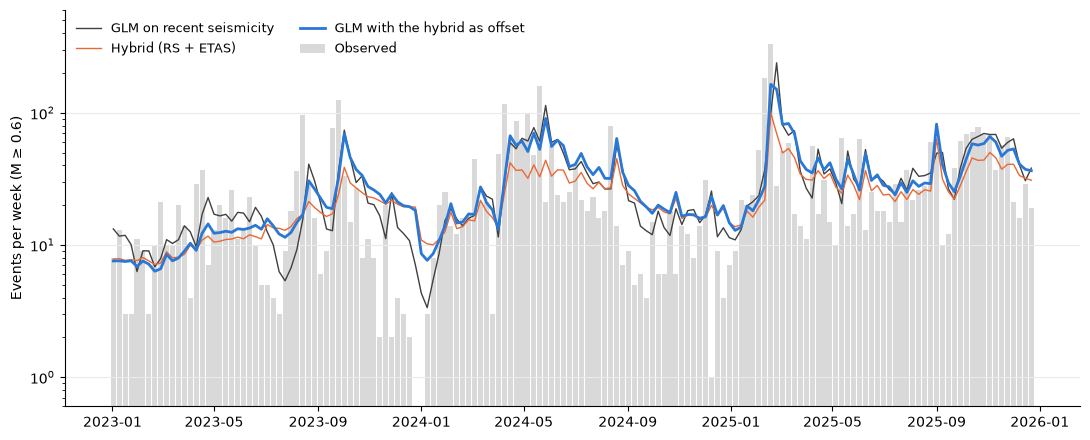

In [8]:
shown_period = slice("2023-01-02", TEST_END)
observed = test["count"].loc[shown_period]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(observed.index, np.maximum(observed, 0.6), width=6, color="0.85", label="Observed")
ax.plot(counts["glm_seismic"].loc[shown_period], color="0.25", linewidth=1, label="GLM on recent seismicity")
ax.plot(counts["physics_rs_etas"].loc[shown_period], color="#eb6834", linewidth=1, label="Hybrid (RS + ETAS)")
ax.plot(counts["glm_offset_hybrid"].loc[shown_period], color="#2a78d6", linewidth=2, label="GLM with the hybrid as offset")
ax.set_yscale("log")
ax.set_ylim(0.6, 600)
ax.set_ylabel("Events per week (M ≥ 0.6)")
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)
ax.grid(True, axis="y", color="0.92", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Summary table for the README

Each main model against the simple benchmark (the mean of the last 4 weeks), on the NB log score: % better (positive = better than the benchmark) with the 95% block-bootstrap interval; * marks intervals that exclude zero.

In [9]:
SUMMARY = {"physics_rs": "Rate-and-state (uplift only)", "physics_etas": "ETAS (earthquakes only)",
           "physics_rs_etas": "Hybrid of Hainzl et al. (uplift + earthquakes)",
           "glm_seismic": "Regression on recent earthquakes (Part 1)", "glm_all": "Same, with GPS inputs (Part 1)",
           "glm_seismic+hybrid": "Regression on recent earthquakes + hybrid forecast"}
rows = {}
for name, label in SUMMARY.items():
    for p, m in periods.items():
        base = log_scores["rolling_mean_4w"][m].mean()
        d = paired_difference(log_scores[name][m], log_scores["rolling_mean_4w"][m])
        better, low, high = (-100 * d[k] / base for k in ["mean_difference", "ci_high", "ci_low"])
        rows.setdefault(label, {})[p] = f"{better:+.1f}% [{low:+.1f}, {high:+.1f}]" + ("*" if low > 0 or high < 0 else "")
pd.DataFrame(rows).T

,2020–2025,2024–2025
Rate-and-state (uplift only),"-1.1% [-3.7, +1.5]","-3.9% [-7.6, -0.8]*"
ETAS (earthquakes only),"+0.7% [-0.9, +2.3]","+1.7% [+0.1, +3.1]*"
Hybrid of Hainzl et al. (uplift + earthquakes),"+1.6% [-0.6, +3.7]","+1.3% [-1.4, +3.4]"
Regression on recent earthquakes (Part 1),"+2.4% [+0.8, +4.2]*","+2.8% [+0.4, +5.1]*"
"Same, with GPS inputs (Part 1)","+2.3% [+0.3, +4.4]*","+2.4% [-0.4, +4.8]"
Regression on recent earthquakes + hybrid forecast,"+2.7% [+1.1, +4.5]*","+2.9% [+0.4, +5.2]*"


## Summary

- **The physics forecast is almost entirely predictable from the seismic features.** A linear regression on the 9 seismic features explains 97–98% of the variance of log(ETAS forecast) and of log(hybrid forecast) over 2013–2025, and both correlate 0.96–0.98 with `log_N` (the cumulative count). So there is little new information for the GLM to gain, which limits what any combination can do.
- **As a feature, the physics forecast helps the GLM only marginally.** With the hybrid's forecast added, the GLM has the best NB log score of all models over 2020–2025 (3.349 against 3.361): 0.34% better, with an interval that excludes zero (the two models are so similar that tiny differences can be measured). In 2024–2025 the gain disappears (0.05%, within noise). With ETAS's forecast added the gain is 0.1% (within noise). The GLM gives the physics feature a weight similar to its strongest seismic features, taking it mostly from `log_N` and `weeks_since_large`.
- **As an offset, it doesn't help on the log score.** The GLMs that correct ETAS or the hybrid score about the same as the plain GLM over 2020–2025 (−0.1% and +0.4%) and slightly worse in 2024–2025 (+0.7%), all within noise. They do have the lowest Poisson deviance of the GLMs (12.6 and 12.9 against 13.4), i.e. they do better in swarm weeks, where ETAS reacts most strongly, but notebook 05 showed the deviance is a blunt test. What the corrections do: the hybrid needs almost no rescaling (factor 0.95 at average feature values) and gains reactivity to the last one or two weeks; ETAS is scaled up by 1.6 at average values (it is low in quiet periods, when its background is tiny).
- **LightGBM gets worse with the physics feature,** significantly worse than the GLM (+1.3% to +1.7%) and no better than its own version without it: trees with only ~360–700 training weeks can't use a smooth, strongly trending input well.
- **Every combined GLM beats the physics model it uses,** significantly so for ETAS over 2020–2025 (about 1.8%); against the hybrid, 0.5–1.6%, within noise.
- **Uplift by this route:** the GLM with the hybrid's forecast against the same GLM with ETAS's: 0.23% better over 2020–2025 (interval excludes zero), 0.02% in 2024–2025 (within noise). That is the only sign of any benefit from the uplift in Part 1 or Part 2, it is far smaller than the gains these tests show for modelling recent seismicity (1–3%), and it disappears in the steady period. Section 2 makes 16 comparisons, so one small significant result in one period could also be chance.
- **P(M ≥ 3):** no combined model beats the best Part 1 forecast (the NB conversion of the 4-week mean, Brier 0.102 / 0.203). The best combined model (GLM with the ETAS offset) is 3% (2020–2025) and 6% (2024–2025) worse on the Brier score, within noise, and significantly worse on log-loss in 2024–2025. As in notebook 06, converting higher, more reactive count forecasts gives over-confident probabilities in busy weeks.

**Answer to question 3:** giving the physics forecast to the ML model as an input changes little. The best combination (the seismic GLM with the hybrid's forecast as a feature) is the best weekly count forecaster overall, but only by 0.3% over the Part 1 GLM, and not at all in 2024–2025; as an offset it doesn't help, LightGBM gets worse, and the probability of M ≥ 3 doesn't improve. The physics forecast is, to 97–98%, a function of the recent seismicity the GLM already uses.

Not tried (optional in the plan): the two loading-history features (uplift above its previous maximum, weeks since the last new maximum).